In [2]:
from pathlib import Path
from google.colab import drive

drive.mount("/content/drive")

archive_dir = Path(
    "/content/drive/MyDrive/mediAI/"
    "03_chembl_egfr_dataset_audit"
)

assert archive_dir.exists(), (
    f"Archive folder not found: {archive_dir}"
)

print("=== mediAI Day 04: Frozen Day 03 Archive ===")
print("Archive path:", archive_dir)
print()

files = sorted(
    [
        path for path in archive_dir.iterdir()
        if path.is_file()
    ],
    key=lambda path: path.name.lower()
)

print(f"Files found: {len(files)}\n")

for path in files:
    size_mb = path.stat().st_size / (1024 * 1024)
    print(f"{path.name:<60} {size_mb:>7.2f} MB")

Mounted at /content/drive
=== mediAI Day 04: Frozen Day 03 Archive ===
Archive path: /content/drive/MyDrive/mediAI/03_chembl_egfr_dataset_audit

Files found: 21

day03_archive_manifest.txt                                      0.00 MB
day03_egfr_assay_metadata.csv                                   0.20 MB
day03_egfr_candidate_records_before_aggregation.csv             2.95 MB
day03_egfr_candidate_records_with_assay_metadata.csv            4.58 MB
day03_egfr_data_card.md                                         0.00 MB
day03_egfr_model_ready_candidate.csv                            1.87 MB
day03_egfr_molecule_level_audit.csv                             1.03 MB
day03_egfr_molecule_level_median_all.csv                        1.40 MB
day03_egfr_morgan_fingerprints.npz                              0.51 MB
day03_egfr_primary_high_confidence_records.csv                  3.43 MB
day03_egfr_primary_model_candidate.csv                          1.48 MB
day03_egfr_raw_ic50_activity.csv              

In [3]:
import numpy as np
import pandas as pd

print("=== mediAI Day 04: Frozen Input Inspection ===")

# These two tables are the likely final modelling-table candidates.
model_table_files = [
    "day03_egfr_primary_model_candidate.csv",
    "day03_egfr_model_ready_candidate.csv",
]

for filename in model_table_files:
    path = archive_dir / filename
    df = pd.read_csv(path)

    print(f"\n--- {filename} ---")
    print("Rows:", len(df))
    print("Columns:", list(df.columns))
    print(
        "Unique standardized SMILES:",
        df["standardized_smiles"].nunique()
        if "standardized_smiles" in df.columns
        else "COLUMN NOT FOUND",
    )

    if "activity_label" in df.columns:
        print(
            "Activity-label counts:",
            df["activity_label"].value_counts().sort_index().to_dict()
        )

# Inspect frozen split assignments.
split_path = archive_dir / "day03_egfr_split_assignments.csv"
split_df = pd.read_csv(split_path)

print("\n--- day03_egfr_split_assignments.csv ---")
print("Rows:", len(split_df))
print("Columns:", list(split_df.columns))
print(
    "Unique standardized SMILES:",
    split_df["standardized_smiles"].nunique()
)

print(
    "Random split counts:",
    split_df["random_split"].value_counts().to_dict()
)

print(
    "Scaffold split counts:",
    split_df["scaffold_split"].value_counts().to_dict()
)

# Inspect frozen Morgan fingerprint archive without training anything.
fp_path = archive_dir / "day03_egfr_morgan_fingerprints.npz"
fp_archive = np.load(fp_path, allow_pickle=False)

print("\n--- day03_egfr_morgan_fingerprints.npz ---")
print("Stored keys:", fp_archive.files)

for key in fp_archive.files:
    value = fp_archive[key]
    print(
        f"{key}: shape={value.shape}, "
        f"dtype={value.dtype}"
    )

=== mediAI Day 04: Frozen Input Inspection ===

--- day03_egfr_primary_model_candidate.csv ---
Rows: 7757
Columns: ['molecule_chembl_id', 'canonical_smiles', 'n_measurements', 'median_pchembl', 'min_pchembl', 'max_pchembl', 'pchembl_range', 'crosses_activity_threshold', 'standardized_smiles', 'activity_label', 'activity_class']
Unique standardized SMILES: 7757
Activity-label counts: {0: 1515, 1: 6242}

--- day03_egfr_model_ready_candidate.csv ---
Rows: 9806
Columns: ['molecule_chembl_id', 'canonical_smiles', 'n_measurements', 'median_pchembl', 'min_pchembl', 'max_pchembl', 'pchembl_range', 'large_measurement_spread', 'activity_label', 'activity_class', 'crosses_activity_threshold', 'standardized_smiles']
Unique standardized SMILES: 9806
Activity-label counts: {0: 2322, 1: 7484}

--- day03_egfr_split_assignments.csv ---
Rows: 7757
Columns: ['molecule_chembl_id', 'standardized_smiles', 'median_pchembl', 'activity_label', 'activity_class', 'murcko_scaffold', 'random_split', 'scaffold_spli

In [4]:
import numpy as np
import pandas as pd

print("=== mediAI Day 04: Load Frozen Day 03 Inputs ===")

# ------------------------------------------------------------
# Load the final 7,757-row modelling table only.
# ------------------------------------------------------------

primary_model_path = (
    archive_dir / "day03_egfr_primary_model_candidate.csv"
)

split_path = (
    archive_dir / "day03_egfr_split_assignments.csv"
)

fingerprint_path = (
    archive_dir / "day03_egfr_morgan_fingerprints.npz"
)

primary_model_df = pd.read_csv(primary_model_path)
split_assignments_df = pd.read_csv(split_path)

fingerprint_archive = np.load(
    fingerprint_path,
    allow_pickle=False,
)

X = fingerprint_archive["X"]
y = fingerprint_archive["y"].astype(int)

# ------------------------------------------------------------
# Confirm dataset / fingerprint / labels are identical.
# ------------------------------------------------------------

assert len(primary_model_df) == 7757
assert X.shape == (7757, 2048)
assert y.shape == (7757,)

assert primary_model_df["standardized_smiles"].is_unique
assert split_assignments_df["standardized_smiles"].is_unique

assert np.array_equal(
    y,
    primary_model_df["activity_label"].astype(int).to_numpy()
), (
    "STOP: fingerprint labels do not match the final Day 03 "
    "primary modelling table."
)

# ------------------------------------------------------------
# Reorder frozen split assignments to the exact table/X order.
# ------------------------------------------------------------

split_lookup = split_assignments_df.set_index(
    "standardized_smiles"
)

assert primary_model_df["standardized_smiles"].isin(
    split_lookup.index
).all()

ordered_splits = split_lookup.loc[
    primary_model_df["standardized_smiles"]
].reset_index()

assert np.array_equal(
    y,
    ordered_splits["activity_label"].astype(int).to_numpy()
), (
    "STOP: ordered frozen split labels do not match fingerprint labels."
)

# ------------------------------------------------------------
# Make immutable train/test index arrays.
# ------------------------------------------------------------

random_train_idx = np.flatnonzero(
    ordered_splits["random_split"].to_numpy() == "train"
)
random_test_idx = np.flatnonzero(
    ordered_splits["random_split"].to_numpy() == "test"
)

scaffold_train_idx = np.flatnonzero(
    ordered_splits["scaffold_split"].to_numpy() == "train"
)
scaffold_test_idx = np.flatnonzero(
    ordered_splits["scaffold_split"].to_numpy() == "test"
)

def verify_split(train_idx, test_idx, split_name):
    assert len(np.intersect1d(train_idx, test_idx)) == 0, (
        f"{split_name}: train/test leakage detected."
    )

    assert len(train_idx) + len(test_idx) == len(y), (
        f"{split_name}: train + test does not cover all structures."
    )

verify_split(
    random_train_idx,
    random_test_idx,
    "random split",
)

verify_split(
    scaffold_train_idx,
    scaffold_test_idx,
    "scaffold split",
)

print("Final structures:", len(primary_model_df))
print("Fingerprint matrix:", X.shape)
print(
    "Class balance:",
    pd.Series(y).value_counts().sort_index().to_dict()
)

print(
    "Random split:",
    f"train={len(random_train_idx):,},",
    f"test={len(random_test_idx):,}",
)

print(
    "Scaffold split:",
    f"train={len(scaffold_train_idx):,},",
    f"test={len(scaffold_test_idx):,}",
)

print("\nFrozen Day 03 inputs are locked and ready.")

=== mediAI Day 04: Load Frozen Day 03 Inputs ===
Final structures: 7757
Fingerprint matrix: (7757, 2048)
Class balance: {0: 1515, 1: 6242}
Random split: train=6,205, test=1,552
Scaffold split: train=6,339, test=1,418

Frozen Day 03 inputs are locked and ready.


In [5]:
import numpy as np
import pandas as pd

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    brier_score_loss,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)

print("=== mediAI Day 04: Fixed Random Forest Evaluation ===")

# ------------------------------------------------------------
# Fixed, predeclared experiment configuration.
# No test-set hyperparameter tuning is allowed.
# ------------------------------------------------------------

RANDOM_SEED = 42

RF_CONFIG = {
    "n_estimators": 500,
    "max_features": "sqrt",
    "min_samples_leaf": 2,
    "class_weight": "balanced_subsample",
    "random_state": RANDOM_SEED,
    "n_jobs": -1,
}

print("Fixed RF configuration:")
for key, value in RF_CONFIG.items():
    print(f"  {key}: {value}")

# ------------------------------------------------------------
# Create a separate Day 04 Drive archive.
# Day 03 archive remains unchanged and frozen.
# ------------------------------------------------------------

day04_dir = (
    Path("/content/drive/MyDrive/mediAI/")
    / "04_egfr_random_forest_comparison"
)

day04_dir.mkdir(parents=True, exist_ok=True)

comparison_path = (
    day04_dir / "day04_model_comparison_metrics.csv"
)

random_predictions_path = (
    day04_dir / "day04_rf_random_split_test_predictions.csv"
)

scaffold_predictions_path = (
    day04_dir / "day04_rf_scaffold_split_test_predictions.csv"
)

output_paths = [
    comparison_path,
    random_predictions_path,
    scaffold_predictions_path,
]

assert not any(path.exists() for path in output_paths), (
    "Day 04 output file(s) already exist in Drive. "
    "Stop here and inspect them instead of overwriting a prior run."
)

# ------------------------------------------------------------
# One fit per already-frozen evaluation split.
# ------------------------------------------------------------

def fit_and_evaluate_rf(train_idx, test_idx, evaluation_scheme):
    model = RandomForestClassifier(**RF_CONFIG)

    model.fit(X[train_idx], y[train_idx])

    y_test = y[test_idx]

    predicted_probability_active = model.predict_proba(
        X[test_idx]
    )[:, 1]

    predicted_label_at_0_5 = (
        predicted_probability_active >= 0.50
    ).astype(int)

    metrics_row = {
        "experiment": evaluation_scheme,
        "model": "Random Forest",
        "train_size": len(train_idx),
        "test_size": len(test_idx),
        "roc_auc": roc_auc_score(
            y_test,
            predicted_probability_active,
        ),
        "pr_auc": average_precision_score(
            y_test,
            predicted_probability_active,
        ),
        "mcc": matthews_corrcoef(
            y_test,
            predicted_label_at_0_5,
        ),
        "balanced_accuracy": balanced_accuracy_score(
            y_test,
            predicted_label_at_0_5,
        ),
        "precision": precision_score(
            y_test,
            predicted_label_at_0_5,
            zero_division=0,
        ),
        "recall": recall_score(
            y_test,
            predicted_label_at_0_5,
            zero_division=0,
        ),
        "f1": f1_score(
            y_test,
            predicted_label_at_0_5,
            zero_division=0,
        ),
        "brier_score": brier_score_loss(
            y_test,
            predicted_probability_active,
        ),
    }

    # Use frozen split metadata in the exact X/y row order.
    prediction_columns = [
        "molecule_chembl_id",
        "standardized_smiles",
        "median_pchembl",
        "activity_label",
        "activity_class",
        "murcko_scaffold",
    ]

    prediction_df = ordered_splits.iloc[
        test_idx
    ][prediction_columns].copy()

    prediction_df["evaluation_scheme"] = evaluation_scheme
    prediction_df[
        "predicted_probability_active"
    ] = predicted_probability_active

    prediction_df[
        "predicted_label_at_0_5"
    ] = predicted_label_at_0_5

    prediction_df["error_type"] = np.select(
        [
            (y_test == 1) & (predicted_label_at_0_5 == 1),
            (y_test == 0) & (predicted_label_at_0_5 == 0),
            (y_test == 1) & (predicted_label_at_0_5 == 0),
            (y_test == 0) & (predicted_label_at_0_5 == 1),
        ],
        [
            "true_positive",
            "true_negative",
            "false_negative",
            "false_positive",
        ],
        default="unknown",
    )

    return metrics_row, prediction_df

print("\nTraining Random Forest on frozen random split...")

rf_random_metrics, rf_random_predictions = (
    fit_and_evaluate_rf(
        random_train_idx,
        random_test_idx,
        "random_split",
    )
)

print("Training Random Forest on frozen scaffold split...")

rf_scaffold_metrics, rf_scaffold_predictions = (
    fit_and_evaluate_rf(
        scaffold_train_idx,
        scaffold_test_idx,
        "scaffold_split",
    )
)

# ------------------------------------------------------------
# Save the two required RF test-prediction files.
# ------------------------------------------------------------

rf_random_predictions.to_csv(
    random_predictions_path,
    index=False,
)

rf_scaffold_predictions.to_csv(
    scaffold_predictions_path,
    index=False,
)

# ------------------------------------------------------------
# Add the already-frozen Day 03 Logistic Regression metrics.
# No manual copying of values.
# ------------------------------------------------------------

logistic_metrics_path = (
    archive_dir / "day03_logistic_baseline_metrics.csv"
)

logistic_metrics_df = pd.read_csv(
    logistic_metrics_path
).copy()

logistic_metrics_df["model"] = "Logistic Regression"

rf_metrics_df = pd.DataFrame([
    rf_random_metrics,
    rf_scaffold_metrics,
])

comparison_columns = [
    "experiment",
    "model",
    "train_size",
    "test_size",
    "roc_auc",
    "pr_auc",
    "mcc",
    "balanced_accuracy",
    "precision",
    "recall",
    "f1",
    "brier_score",
]

comparison_df = pd.concat(
    [
        logistic_metrics_df[comparison_columns],
        rf_metrics_df[comparison_columns],
    ],
    ignore_index=True,
)

comparison_df.to_csv(
    comparison_path,
    index=False,
)

# ------------------------------------------------------------
# Print only verified metrics.
#

=== mediAI Day 04: Fixed Random Forest Evaluation ===
Fixed RF configuration:
  n_estimators: 500
  max_features: sqrt
  min_samples_leaf: 2
  class_weight: balanced_subsample
  random_state: 42
  n_jobs: -1

Training Random Forest on frozen random split...
Training Random Forest on frozen scaffold split...


In [6]:
comparison_check = pd.read_csv(
    day04_dir / "day04_model_comparison_metrics.csv"
)

print("=== Verified Day 04 Model Comparison ===")

print(
    comparison_check[
        [
            "experiment",
            "model",
            "roc_auc",
            "pr_auc",
            "mcc",
            "balanced_accuracy",
            "precision",
            "recall",
            "f1",
            "brier_score",
        ]
    ].round(4).to_string(index=False)
)

print("\nFiles saved in:")
print(day04_dir)

=== Verified Day 04 Model Comparison ===
    experiment               model  roc_auc  pr_auc    mcc  balanced_accuracy  precision  recall     f1  brier_score
  random_split Logistic Regression   0.9097  0.9715 0.6314             0.8378     0.9436  0.8967 0.9195       0.0976
scaffold_split Logistic Regression   0.8906  0.9643 0.5949             0.8214     0.9373  0.8813 0.9084       0.1096
  random_split       Random Forest   0.9398  0.9830 0.6731             0.8435     0.9407  0.9279 0.9343       0.0787
scaffold_split       Random Forest   0.9410  0.9837 0.6618             0.8399     0.9391  0.9217 0.9303       0.0816

Files saved in:
/content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison


=== mediAI Day 04: Model Comparison Audit ===

=== Error Summary at Fixed 0.50 Threshold ===
              model     experiment  test_size  true_negatives  false_positives  false_negatives  true_positives  correct_predictions  total_errors
Logistic Regression   random_split       1552             236               67              129            1120                 1356           196
      Random Forest   random_split       1552             230               73               90            1159                 1389           163
Logistic Regression scaffold_split       1418             214               67              135            1002                 1216           202
      Random Forest scaffold_split       1418             213               68               89            1048                 1261           157


/tmp/ipykernel_724/3817348671.py:189: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


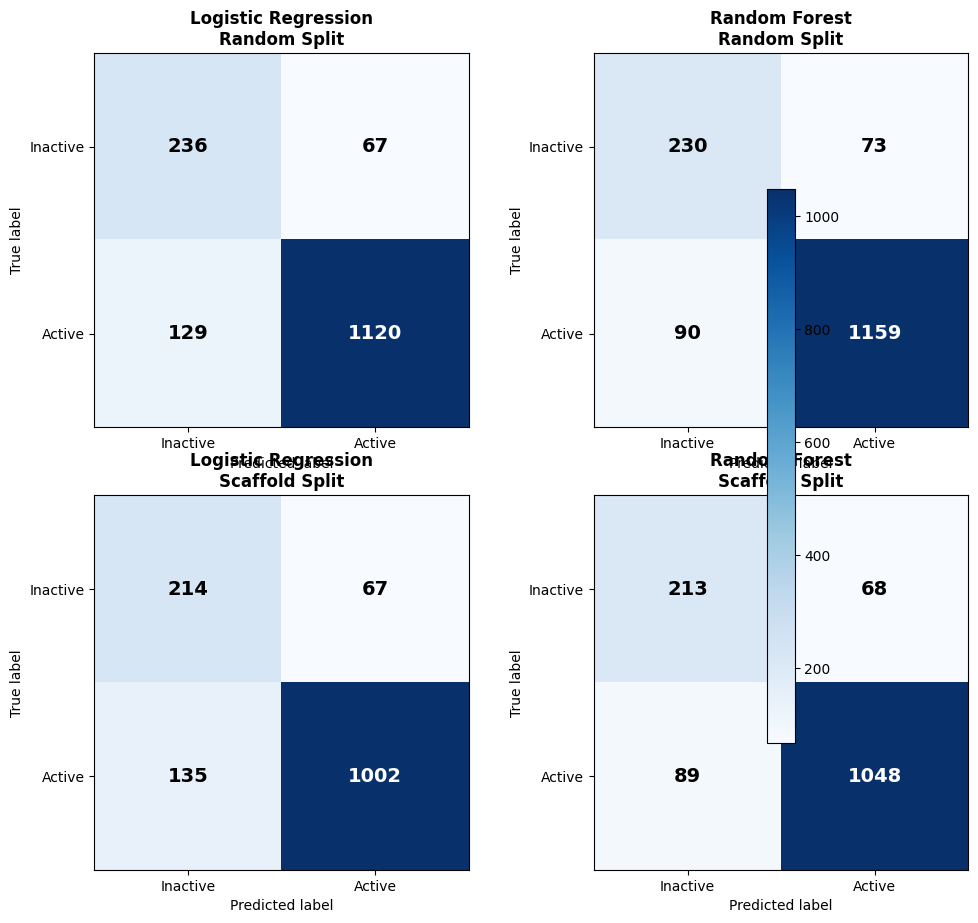

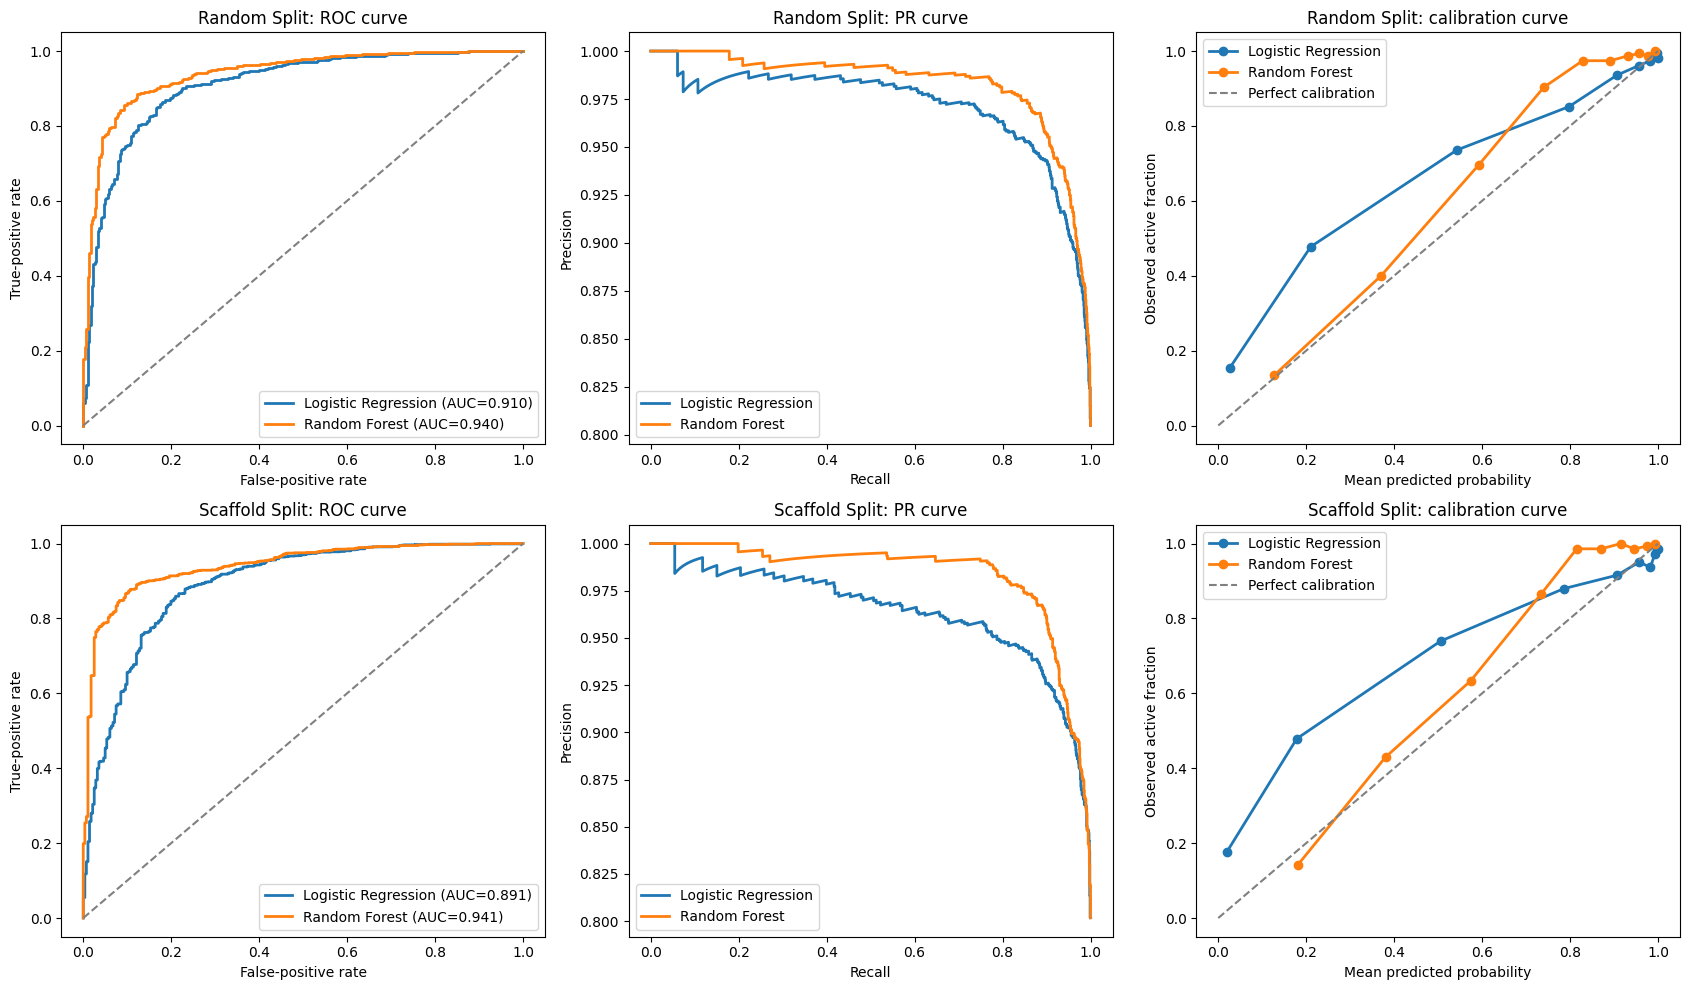


Saved Day 04 audit artifacts:
- /content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/day04_model_comparison_error_summary.csv
- /content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/day04_model_comparison_confusion_matrices.png
- /content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/day04_model_comparison_evaluation_curves.png


In [7]:
import matplotlib.pyplot as plt

from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    confusion_matrix,
    roc_auc_score,
    roc_curve,
    precision_recall_curve,
)

print("=== mediAI Day 04: Model Comparison Audit ===")

# ------------------------------------------------------------
# Load saved predictions only.
# No model is trained and no setting is changed in this cell.
# ------------------------------------------------------------

prediction_sources = [
    (
        "Logistic Regression",
        "random_split",
        archive_dir / "day03_random_split_test_predictions.csv",
    ),
    (
        "Random Forest",
        "random_split",
        day04_dir / "day04_rf_random_split_test_predictions.csv",
    ),
    (
        "Logistic Regression",
        "scaffold_split",
        archive_dir / "day03_scaffold_split_test_predictions.csv",
    ),
    (
        "Random Forest",
        "scaffold_split",
        day04_dir / "day04_rf_scaffold_split_test_predictions.csv",
    ),
]

prediction_data = {}

for model_name, evaluation_scheme, file_path in prediction_sources:
    assert file_path.exists(), (
        f"Missing saved prediction file: {file_path}"
    )

    df = pd.read_csv(file_path).copy()

    required_columns = [
        "activity_label",
        "predicted_probability_active",
    ]

    missing_columns = [
        column for column in required_columns
        if column not in df.columns
    ]

    assert not missing_columns, (
        f"{file_path.name} is missing: {missing_columns}"
    )

    if "predicted_label_at_0_5" not in df.columns:
        df["predicted_label_at_0_5"] = (
            df["predicted_probability_active"] >= 0.50
        ).astype(int)

    prediction_data[
        (model_name, evaluation_scheme)
    ] = df

# ------------------------------------------------------------
# Create an error-count summary from the stored predictions.
# ------------------------------------------------------------

error_rows = []

for (model_name, evaluation_scheme), df in prediction_data.items():
    y_true = df["activity_label"].astype(int).to_numpy()
    y_pred = df["predicted_label_at_0_5"].astype(int).to_numpy()

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1],
    ).ravel()

    error_rows.append(
        {
            "model": model_name,
            "experiment": evaluation_scheme,
            "test_size": len(df),
            "true_negatives": tn,
            "false_positives": fp,
            "false_negatives": fn,
            "true_positives": tp,
            "correct_predictions": int(tn + tp),
            "total_errors": int(fp + fn),
        }
    )

error_summary_df = pd.DataFrame(error_rows)

error_summary_path = (
    day04_dir / "day04_model_comparison_error_summary.csv"
)

error_summary_df.to_csv(
    error_summary_path,
    index=False,
)

print("\n=== Error Summary at Fixed 0.50 Threshold ===")
print(error_summary_df.to_string(index=False))

# ------------------------------------------------------------
# Save four side-by-side confusion matrices.
# ------------------------------------------------------------

plot_order = [
    ("Logistic Regression", "random_split"),
    ("Random Forest", "random_split"),
    ("Logistic Regression", "scaffold_split"),
    ("Random Forest", "scaffold_split"),
]

fig, axes = plt.subplots(
    2,
    2,
    figsize=(10, 9),
)

for ax, (model_name, evaluation_scheme) in zip(
    axes.ravel(),
    plot_order,
):
    df = prediction_data[(model_name, evaluation_scheme)]

    cm = confusion_matrix(
        df["activity_label"].astype(int),
        df["predicted_label_at_0_5"].astype(int),
        labels=[0, 1],
    )

    image = ax.imshow(
        cm,
        cmap="Blues",
    )

    for row in range(2):
        for column in range(2):
            ax.text(
                column,
                row,
                str(cm[row, column]),
                ha="center",
                va="center",
                fontsize=14,
                fontweight="bold",
                color="white" if cm[row, column] > cm.max() / 2 else "black",
            )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(["Inactive", "Active"])
    ax.set_yticklabels(["Inactive", "Active"])

    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")

    readable_split = evaluation_scheme.replace(
        "_",
        " ",
    ).title()

    ax.set_title(
        f"{model_name}\n{readable_split}",
        fontweight="bold",
    )

fig.colorbar(
    image,
    ax=axes.ravel().tolist(),
    shrink=0.8,
)

plt.tight_layout()

confusion_figure_path = (
    day04_dir / "day04_model_comparison_confusion_matrices.png"
)

plt.savefig(
    confusion_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

# ------------------------------------------------------------
# Save ROC, PR, and calibration curves for both split schemes.
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(17, 10),
)

for row_index, evaluation_scheme in enumerate(
    ["random_split", "scaffold_split"]
):
    roc_ax = axes[row_index, 0]
    pr_ax = axes[row_index, 1]
    calibration_ax = axes[row_index, 2]

    for model_name in [
        "Logistic Regression",
        "Random Forest",
    ]:
        df = prediction_data[
            (model_name, evaluation_scheme)
        ]

        y_true = df["activity_label"].astype(int).to_numpy()
        y_probability = df[
            "predicted_probability_active"
        ].to_numpy()

        fpr, tpr, _ = roc_curve(
            y_true,
            y_probability,
        )

        precision, recall, _ = precision_recall_curve(
            y_true,
            y_probability,
        )

        fraction_positive, mean_predicted = calibration_curve(
            y_true,
            y_probability,
            n_bins=10,
            strategy="quantile",
        )

        auc_value = roc_auc_score(
            y_true,
            y_probability,
        )

        roc_ax.plot(
            fpr,
            tpr,
            linewidth=2,
            label=f"{model_name} (AUC={auc_value:.3f})",
        )

        pr_ax.plot(
            recall,
            precision,
            linewidth=2,
            label=model_name,
        )

        calibration_ax.plot(
            mean_predicted,
            fraction_positive,
            marker="o",
            linewidth=2,
            label=model_name,
        )

    readable_split = evaluation_scheme.replace(
        "_",
        " ",
    ).title()

    roc_ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
    )
    roc_ax.set_title(f"{readable_split}: ROC curve")
    roc_ax.set_xlabel("False-positive rate")
    roc_ax.set_ylabel("True-positive rate")
    roc_ax.legend()

    pr_ax.set_title(f"{readable_split}: PR curve")
    pr_ax.set_xlabel("Recall")
    pr_ax.set_ylabel("Precision")
    pr_ax.legend()

    calibration_ax.plot(
        [0, 1],
        [0, 1],
        linestyle="--",
        color="gray",
        label="Perfect calibration",
    )
    calibration_ax.set_title(
        f"{readable_split}: calibration curve"
    )
    calibration_ax.set_xlabel("Mean predicted probability")
    calibration_ax.set_ylabel("Observed active fraction")
    calibration_ax.legend()

plt.tight_layout()

curve_figure_path = (
    day04_dir / "day04_model_comparison_evaluation_curves.png"
)

plt.savefig(
    curve_figure_path,
    dpi=200,
    bbox_inches="tight",
)

plt.show()

print("\nSaved Day 04 audit artifacts:")
print("-", error_summary_path)
print("-", confusion_figure_path)
print("-", curve_figure_path)

In [8]:
from pathlib import Path

print("=== mediAI Day 04: Random Forest Comparison Data Card ===")

comparison_df = pd.read_csv(
    day04_dir / "day04_model_comparison_metrics.csv"
)

error_summary_df = pd.read_csv(
    day04_dir / "day04_model_comparison_error_summary.csv"
)

def get_row(dataframe, experiment, model):
    rows = dataframe[
        (dataframe["experiment"] == experiment)
        & (dataframe["model"] == model)
    ]

    assert len(rows) == 1, (
        f"Expected exactly one row for {model}, {experiment}."
    )

    return rows.iloc[0]

random_lr = get_row(
    comparison_df,
    "random_split",
    "Logistic Regression",
)

random_rf = get_row(
    comparison_df,
    "random_split",
    "Random Forest",
)

scaffold_lr = get_row(
    comparison_df,
    "scaffold_split",
    "Logistic Regression",
)

scaffold_rf = get_row(
    comparison_df,
    "scaffold_split",
    "Random Forest",
)

random_lr_errors = get_row(
    error_summary_df,
    "random_split",
    "Logistic Regression",
)

random_rf_errors = get_row(
    error_summary_df,
    "random_split",
    "Random Forest",
)

scaffold_lr_errors = get_row(
    error_summary_df,
    "scaffold_split",
    "Logistic Regression",
)

scaffold_rf_errors = get_row(
    error_summary_df,
    "scaffold_split",
    "Random Forest",
)

random_error_reduction = int(
    random_lr_errors["total_errors"]
    - random_rf_errors["total_errors"]
)

scaffold_error_reduction = int(
    scaffold_lr_errors["total_errors"]
    - scaffold_rf_errors["total_errors"]
)

data_card = f"""# mediAI Day 04 — Fixed Random Forest Comparison Data Card

## Project question

On the frozen Day 03 ChEMBL EGFR dataset and unchanged evaluation splits,
does one predeclared Random Forest baseline improve on the transparent
Logistic Regression reference model?

## Frozen Day 03 inputs

- Source target: human EGFR (`CHEMBL203`) from ChEMBL public data
- Final standardized structures: 7,757
- Active labels: 6,242
- Inactive labels: 1,515
- Molecular representation: radius-2 Morgan fingerprints, 2,048 bits
- Random split: 6,205 train / 1,552 test
- Scaffold split: 6,339 train / 1,418 test
- Random seed: 42
- Classification threshold: 0.50

## Models compared

### Transparent reference

- Logistic Regression
- Class weighting: balanced
- Solver: liblinear
- Maximum iterations: 2,000

### Fixed Random Forest

- Estimators: 500
- Maximum features per split: sqrt
- Minimum samples per leaf: 2
- Class weighting: balanced_subsample
- Random seed: 42
- Parallel workers: all available CPU cores

No hyperparameter selection was performed from held-out test results.

## Test-set performance

| Split | Model | ROC-AUC | PR-AUC | MCC | Balanced accuracy | Precision | Recall | F1 | Brier score |
|---|---|---:|---:|---:|---:|---:|---:|---:|---:|
| Random | Logistic Regression | {random_lr["roc_auc"]:.4f} | {random_lr["pr_auc"]:.4f} | {random_lr["mcc"]:.4f} | {random_lr["balanced_accuracy"]:.4f} | {random_lr["precision"]:.4f} | {random_lr["recall"]:.4f} | {random_lr["f1"]:.4f} | {random_lr["brier_score"]:.4f} |
| Random | Random Forest | {random_rf["roc_auc"]:.4f} | {random_rf["pr_auc"]:.4f} | {random_rf["mcc"]:.4f} | {random_rf["balanced_accuracy"]:.4f} | {random_rf["precision"]:.4f} | {random_rf["recall"]:.4f} | {random_rf["f1"]:.4f} | {random_rf["brier_score"]:.4f} |
| Scaffold | Logistic Regression | {scaffold_lr["roc_auc"]:.4f} | {scaffold_lr["pr_auc"]:.4f} | {scaffold_lr["mcc"]:.4f} | {scaffold_lr["balanced_accuracy"]:.4f} | {scaffold_lr["precision"]:.4f} | {scaffold_lr["recall"]:.4f} | {scaffold_lr["f1"]:.4f} | {scaffold_lr["brier_score"]:.4f} |
| Scaffold | Random Forest | {scaffold_rf["roc_auc"]:.4f} | {scaffold_rf["pr_auc"]:.4f} | {scaffold_rf["mcc"]:.4f} | {scaffold_rf["balanced_accuracy"]:.4f} | {scaffold_rf["precision"]:.4f} | {scaffold_rf["recall"]:.4f} | {scaffold_rf["f1"]:.4f} | {scaffold_rf["brier_score"]:.4f} |

## Fixed-threshold error audit

| Split | Model | False positives | False negatives | Total errors |
|---|---|---:|---:|---:|
| Random | Logistic Regression | {int(random_lr_errors["false_positives"])} | {int(random_lr_errors["false_negatives"])} | {int(random_lr_errors["total_errors"])} |
| Random | Random Forest | {int(random_rf_errors["false_positives"])} | {int(random_rf_errors["false_negatives"])} | {int(random_rf_errors["total_errors"])} |
| Scaffold | Logistic Regression | {int(scaffold_lr_errors["false_positives"])} | {int(scaffold_lr_errors["false_negatives"])} | {int(scaffold_lr_errors["total_errors"])} |
| Scaffold | Random Forest | {int(scaffold_rf_errors["false_positives"])} | {int(scaffold_rf_errors["false_negatives"])} | {int(scaffold_rf_errors["total_errors"])} |

## Result summary

- Random Forest improved ROC-AUC, PR-AUC, MCC, balanced accuracy, recall,
  F1, and Brier score on both frozen evaluation schemes.
- At the fixed 0.50 threshold, Random Forest made
  {random_error_reduction} fewer errors on the random test split and
  {scaffold_error_reduction} fewer errors on the scaffold test split.
- The largest change was fewer false negatives:
  {int(random_lr_errors["false_negatives"] - random_rf_errors["false_negatives"])}
  fewer on the random split and
  {int(scaffold_lr_errors["false_negatives"] - scaffold_rf_errors["false_negatives"])}
  fewer on the scaffold split.
- Random Forest is the leading internal predictive baseline in this
  fixed comparison. Logistic Regression remains the simpler,
  more interpretable reference model.

## Saved artifacts

- `day04_model_comparison_metrics.csv`
- `day04_rf_random_split_test_predictions.csv`
- `day04_rf_scaffold_split_test_predictions.csv`
- `day04_model_comparison_error_summary.csv`
- `day04_model_comparison_confusion_matrices.png`
- `day04_model_comparison_evaluation_curves.png`

## Limitations

1. This is one internal comparison on one curated public ChEMBL dataset.
2. The test splits were used only for final evaluation, not parameter tuning,
   but model selection across baselines is still an internal research step.
3. A scaffold split is stronger than a random split but is not external,
   temporal, prospective, or experimental validation.
4. Lower Brier scores are favourable probability-score results; they do not
   prove perfect calibration.
5. The activity label depends on the predeclared median pChEMBL 6.0 threshold.
6. This workflow does not predict clinical efficacy, safety, dosing,
   pharmacokinetics, toxicity, patient benefit, or regulatory approval.

## Next steps

1. Archive the verified Day 04 artifacts.
2. Publish the Day 04 notebook and selected results to GitHub.
3. Use the documented results—not hype—to create the EGFR flagship video.
"""

data_card_path = (
    day04_dir / "day04_random_forest_comparison_data_card.md"
)

data_card_path.write_text(
    data_card,
    encoding="utf-8",
)

assert data_card_path.exists()
assert data_card_path.stat().st_size > 0

print("Saved data card:")
print(data_card_path)

print("\nDay 04 conclusion:")
print(
    "Random Forest is the leading internal baseline in this "
    "fixed comparison; no external-validation claim is made."
)

=== mediAI Day 04: Random Forest Comparison Data Card ===
Saved data card:
/content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/day04_random_forest_comparison_data_card.md

Day 04 conclusion:
Random Forest is the leading internal baseline in this fixed comparison; no external-validation claim is made.


In [9]:
from datetime import datetime

print("=== mediAI Day 04: Archive Verification ===")

expected_day04_files = [
    "day04_model_comparison_metrics.csv",
    "day04_rf_random_split_test_predictions.csv",
    "day04_rf_scaffold_split_test_predictions.csv",
    "day04_model_comparison_error_summary.csv",
    "day04_model_comparison_confusion_matrices.png",
    "day04_model_comparison_evaluation_curves.png",
    "day04_random_forest_comparison_data_card.md",
]

found_files = []
missing_files = []

for filename in expected_day04_files:
    file_path = day04_dir / filename

    if file_path.exists() and file_path.stat().st_size > 0:
        found_files.append(file_path)
    else:
        missing_files.append(filename)

manifest_lines = [
    "mediAI Day 04 — Archive Manifest",
    f"Created: {datetime.now().isoformat(timespec='seconds')}",
    f"Archive folder: {day04_dir}",
    "",
    f"Files verified: {len(found_files)}",
    f"Missing files: {len(missing_files)}",
    "",
    "Verified files:",
]

for file_path in found_files:
    size_kb = file_path.stat().st_size / 1024
    manifest_lines.append(
        f"- {file_path.name} ({size_kb:.1f} KB)"
    )

if missing_files:
    manifest_lines.extend(
        [
            "",
            "Missing files:",
            *[f"- {filename}" for filename in missing_files],
        ]
    )

manifest_path = day04_dir / "day04_archive_manifest.txt"

manifest_path.write_text(
    "\n".join(manifest_lines),
    encoding="utf-8",
)

print(f"Archive folder: {day04_dir}")
print(f"Files verified: {len(found_files)}")
print(f"Missing files: {len(missing_files)}")

print("\nVerified files:")
for file_path in found_files:
    print("-", file_path.name)

print("\nManifest saved:")
print(manifest_path)

assert len(missing_files) == 0, (
    "Archive is incomplete. Do not move to GitHub yet."
)

=== mediAI Day 04: Archive Verification ===
Archive folder: /content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison
Files verified: 7
Missing files: 0

Verified files:
- day04_model_comparison_metrics.csv
- day04_rf_random_split_test_predictions.csv
- day04_rf_scaffold_split_test_predictions.csv
- day04_model_comparison_error_summary.csv
- day04_model_comparison_confusion_matrices.png
- day04_model_comparison_evaluation_curves.png
- day04_random_forest_comparison_data_card.md

Manifest saved:
/content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/day04_archive_manifest.txt


In [10]:
import shutil

print("=== mediAI Day 04: GitHub Publish Folder ===")

github_publish_day04_dir = (
    day04_dir / "github_publish_day04"
)

github_publish_day04_dir.mkdir(
    parents=True,
    exist_ok=True,
)

github_public_day04_files = [
    "day04_random_forest_comparison_data_card.md",
    "day04_model_comparison_metrics.csv",
    "day04_model_comparison_error_summary.csv",
    "day04_model_comparison_confusion_matrices.png",
    "day04_model_comparison_evaluation_curves.png",
]

copied_files = []
missing_files = []

for filename in github_public_day04_files:
    source_path = day04_dir / filename
    destination_path = (
        github_publish_day04_dir / filename
    )

    if source_path.exists() and source_path.stat().st_size > 0:
        shutil.copy2(
            source_path,
            destination_path,
        )
        copied_files.append(filename)
    else:
        missing_files.append(filename)

print("GitHub publish folder:")
print(github_publish_day04_dir)

print(f"\nFiles copied: {len(copied_files)}")
print(f"Missing files: {len(missing_files)}")

print("\nReady for GitHub:")
for filename in copied_files:
    print("-", filename)

assert len(missing_files) == 0, (
    "Some required public artifacts are missing."
)

=== mediAI Day 04: GitHub Publish Folder ===
GitHub publish folder:
/content/drive/MyDrive/mediAI/04_egfr_random_forest_comparison/github_publish_day04

Files copied: 5
Missing files: 0

Ready for GitHub:
- day04_random_forest_comparison_data_card.md
- day04_model_comparison_metrics.csv
- day04_model_comparison_error_summary.csv
- day04_model_comparison_confusion_matrices.png
- day04_model_comparison_evaluation_curves.png


In [11]:
from google.colab import files
import shutil

zip_path = shutil.make_archive(
    "/content/mediAI_day04_github_publish",
    "zip",
    github_publish_day04_dir,
)

print("Created ZIP:")
print(zip_path)

files.download(zip_path)

Created ZIP:
/content/mediAI_day04_github_publish.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>